In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
%cd "drive/MyDrive/reasoning"

/content/drive/MyDrive/reasoning


In [3]:
from helpers.qwen3 import download_qwen3_small, Qwen3Tokenizer, Qwen3Model, QWEN_CONFIG_06_B

def load_model_and_tokenizer(which_model, device, use_compile, local_dir="qwen3"):
    if which_model == "base":
        download_qwen3_small(kind="base", tokenizer_only=False, out_dir="math")
        tokenizer_path = "math/tokenizer-base.json"
        model_path = "math/qwen3-0.6B-base.pth"
        tokenizer = Qwen3Tokenizer(tokenizer_file_path=tokenizer_path)
    elif which_model == "reasoning":
        download_qwen3_small(kind="reasoning", tokenizer_only="False", out_dir="math")
        tokenizer_path = "math/tokenizer-reasoning.json"
        model_path = "math/qwen3-0.6B-reasoning.pth"
        tokenizer = Qwen3Tokenizer(tokenizer_file_path=tokenizer_path, apply_chat_template=True, add_generation_prompt=True, add_thinking=True,)
    else:
        raise ValueError(f"Invalid choice")
    
    model = Qwen3Model(QWEN_CONFIG_06_B)
    model.load_state_dict(torch.load(model_path))
    model.to(device)
    
    if use_compile:
        torch._dynamo.config.allow_unspec_int_on_nn_module = True
        model = torch.compile(model)
        
    return model, tokenizer

In [4]:
import torch
device = torch.device("cpu")
model, tokenizer = load_model_and_tokenizer(which_model="base", device=device, use_compile=False)

✓ math/qwen3-0.6B-base.pth already up-to-date


In [5]:
def render_prompt(prompt):
    template = (
        "You are a helpful math assistant.\n"
        "Answer the question and write the final result on a new line as:\n"
        "\\boxed{ANSWER}\n\n"
        f"Question:\n{prompt}\n\nAnswer:"
    )
    return template

raw_prompt = (
    "Half the value of $3x-9$ is $x+37$. "
    "What is the value of $x$?"
)
prompt = render_prompt(raw_prompt)
print(prompt)

You are a helpful math assistant.
Answer the question and write the final result on a new line as:
\boxed{ANSWER}

Question:
Half the value of $3x-9$ is $x+37$. What is the value of $x$?

Answer:


In [6]:
import torch
from helpers.qwen3 import KVCache

@torch.inference_mode()
def generate_text_basic_stream_cache(model, token_ids, max_new_tokens, eos_token_id=None):
    model.eval()
    cache = KVCache(n_layers=model.cfg["n_layers"])
    model.reset_kv_cache()
    
    out = model(token_ids, cache=cache)[:, -1]    
    for step in range(max_new_tokens):
        next_token = torch.argmax(out, dim=-1, keepdim=True)
        
        if (eos_token_id is not None and torch.all(next_token == eos_token_id)):
            break
        
        yield next_token
        if step + 1 < max_new_tokens:
            out = model(next_token, cache=cache)[:, -1]

In [7]:
def generate_text_stream_concat_flex(model, tokenizer, prompt, device, max_new_tokens, verbose=False, generate_func=None, **generate_kwargs,):
    if generate_func is None:
        generate_func = generate_text_basic_stream_cache
        
    input_ids = torch.tensor(tokenizer.encode(prompt), device=device).unsqueeze(0)
    generated_ids = []
    for token in generate_func(model=model, token_ids=input_ids, max_new_tokens=max_new_tokens, eos_token_id=tokenizer.eos_token_id, **generate_kwargs,):
        next_token_id = token.squeeze(0)
        generated_ids.append(next_token_id.item())
        if verbose:
            print(tokenizer.decode(next_token_id.tolist()), end="", flush=True)
    return tokenizer.decode(generated_ids)

In [8]:
def scale_logits_by_temperature(logits, temperature):
    if temperature <= 0:
        raise ValueError("Temperature must be positive")
    return logits / temperature

In [9]:
def top_p_filter(probas, top_p):
    if top_p is None or top_p >= 1.0:
        return probas
    
    sorted_probas, sorted_idx = torch.sort(probas, dim=1, descending=True)
    cumprobas = torch.cumsum(sorted_probas, dim=1)
    prefix = cumprobas - sorted_probas
    
    keep = prefix < top_p
    keep[:, 0] = True
    keep_sorted = torch.where(keep, sorted_probas, torch.zeros_like(sorted_probas))
    
    filtered = torch.zeros_like(probas).scatter(1, sorted_idx, keep_sorted)
    denom = torch.sum(filtered, dim=1, keepdim=True).clamp_min(1e-12)
    return filtered / denom

In [10]:
from helpers.qwen3 import KVCache

@torch.inference_mode()
def generate_text_top_p_stream_cache(model, token_ids, max_new_tokens, eos_token_id=None, temperature=0., top_p=None):
    model.eval()
    cache = KVCache(n_layers=model.cfg["n_layers"])
    model.reset_kv_cache()
    
    out = model(token_ids, cache=cache)[:, -1]    
    for step in range(max_new_tokens):
        orig_device = token_ids.device
        if temperature is None or temperature == 0.0:
            next_token = torch.argmax(out, dim=-1, keepdim=True)
        else:
            logits = scale_logits_by_temperature(out, temperature)
            probas = torch.softmax(logits, dim=-1)
            probas = top_p_filter(probas, top_p)
            next_token = torch.multinomial(probas.cpu(), num_samples=1)
            next_token = next_token.to(orig_device)
        
        if (eos_token_id is not None and torch.all(next_token == eos_token_id)):
            break
        
        yield next_token
        if step + 1 < max_new_tokens:
            out = model(next_token, cache=cache)[:, -1]

In [11]:
raw_prompt = (
    "Half the value of $3x-9$ is $x+37$. "
    "What is the value of $x$?"
)
prompt = render_prompt(raw_prompt)
prompt_cot = prompt + " \n\nExplain step by step."

In [12]:
response_1 = generate_text_stream_concat_flex(
    model, tokenizer, prompt_cot, device, 
    max_new_tokens=2048, verbose=True, 
    generate_func=generate_text_top_p_stream_cache,
    temperature=0.9,
    top_p=0.9
)

 First, we need to set up the equation based on the information given in the question:

Since half the value of $3x-9$ is $x+37$, we can write:

$\frac{1}{2} \cdot (3x-9) = x+37$

Next, we can solve this equation to find the value of $x$.

First, we multiply both sides of the equation by 2 to eliminate the fraction:

$3x-9 = 2(x+37)$

Then, we distribute the 2 on the right side of the equation:

$3x-9 = 2x + 74$

Now, we want to get all the $x$ terms on one side of the equation and the constants on the other side. To do this, we subtract $2x$ from both sides:

$3x - 2x - 9 = 2x - 2x + 74$

Simplifying both sides gives us:

$x - 9 = 74$

Next, we add 9 to both sides to isolate $x$:

$x - 9 + 9 = 74 + 9$

Simplifying both sides gives us:

$x = 83$

So the value of $x$ is 83.

In [13]:
response_2 = generate_text_stream_concat_flex(
    model, tokenizer, prompt_cot, device, 
    max_new_tokens=2048, verbose=True, 
    generate_func=generate_text_top_p_stream_cache,
    temperature=0.9,
    top_p=0.9
)

 To solve this problem, we will follow these steps:

1. Set up the equation based on the given information:
   - Half the value of \(3x - 9\) is equal to \(x + 37\).

2. Convert the equation to an algebraic expression for solving it:
   - Half the value of \(3x - 9\) is \(\frac{1}{2}(3x - 9)\).

3. Translate the given information into an equation:
   - The equation becomes \(\frac{1}{2}(3x - 9) = x + 37\).

4. Solve the equation by isolating \(x\):
   - First, multiply both sides of the equation by 2 to eliminate the fraction:
     \[
     2 \cdot \frac{1}{2}(3x - 9) = 2(x + 37)
     \]
   - This simplifies to:
     \[
     3x - 9 = 2x + 74
     \]

5. Isolate \(x\) by moving all terms involving \(x\) to one side of the equation:
   - Subtract \(2x\) from both sides:
     \[
     3x - 2x - 9 = 74
     \]
   - Simplify:
     \[
     x - 9 = 74
     \]

6. Solve for \(x\) by adding 9 to both sides:
   - Add 9 to both sides:
     \[
     x - 9 + 9 = 74 + 9
     \]
   - Simplify:
     \[
 

In [14]:
print("Response 1 characters:", len(response_1))
print("Response 1 tokens:", len(tokenizer.encode(response_1)))
print("Response 2 characters:", len(response_2))
print("Response 2 tokens:", len(tokenizer.encode(response_2)))

Response 1 characters: 783
Response 1 tokens: 273
Response 2 characters: 1097
Response 2 tokens: 387


In [15]:
def get_last_boxed(text):
    boxed_start_idx = text.rfind(r"\boxed")
    if boxed_start_idx == -1:
        return None
    current_idx = boxed_start_idx + len(r"\boxed")
    while current_idx < len(text) and text[current_idx].isspace():
        current_idx += 1
    if current_idx >= len(text) or text[current_idx] != "{":
        return None
    current_idx += 1
    brace_depth = 1
    content_start_idx = current_idx
    while current_idx < len(text) and brace_depth > 0:
        char = text[current_idx]
        if char == "{":
            brace_depth += 1
        elif char == "}":
            brace_depth -= 1
        current_idx += 1
    if brace_depth != 0:
        return None
    return text[content_start_idx:current_idx-1]

import re
RE_NUMBER = re.compile(
    r"-?(?:\d+/\d+|\d+(?:\.\d+)?(?:[eE][+-]?\d+)?)"
)
def extract_final_candidate(text, fallback="number_then_full"):
    result = ""
    if text:
        boxed = get_last_boxed(text.strip())
        if boxed:
            result = boxed.strip().strip("$ ")
        elif fallback in ("number_then_full", "number_only"):
            m = RE_NUMBER.findall(text)
            if m:
                result = m[-1]
            elif fallback == "number_then_full":
                result = text
    return result

In [22]:
import math

def heuristic_score(
    answer,
    prompt=None,
    brevity_bonus=500.0,
    boxed_bonus=2.0,
    extract_bonus=1.0,
    fulltext_bonus=0.0,
):
    score = 0.0
    cand = extract_final_candidate(answer, fallback=None)
    if cand:
        score += boxed_bonus
    else:
        cand = extract_final_candidate(answer, fallback="number_then_full")
        if cand:
            score += fulltext_bonus
    
    score += 1.5 * math.exp(-len(answer) / brevity_bonus)
    return score

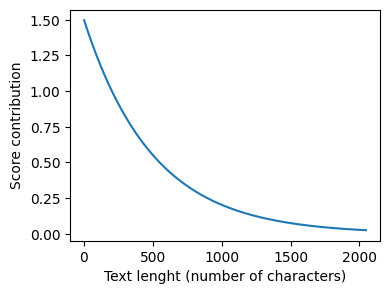

In [19]:
import matplotlib.pyplot as plt

def plot_brevity_curve(brevity_bonus, max_len=2048):
    lengths = torch.arange(1, max_len)
    scores = 1.5 * torch.exp(-lengths / brevity_bonus)
    
    plt.figure(figsize=(4, 3))
    plt.plot(lengths, scores)
    plt.xlabel("Text lenght (number of characters)")
    plt.ylabel("Score contribution")
    plt.show()
    
plot_brevity_curve(500)

In [24]:
print(round(heuristic_score(response_1), 3))
print(round(heuristic_score(response_2), 3))

0.313
2.167


In [25]:
@torch.inference_mode()
def calc_next_token_probas(model, tokenizer, prompt, device, show=True):
    token_ids = torch.tensor(tokenizer.encode(prompt), device=device)
    logits = model(token_ids.unsqueeze(0)).squeeze(0)
    all_probas = torch.softmax(logits, dim=-1)
    
    t_idx = torch.arange(0, token_ids.shape[0] - 1, device=device)
    next_ids = token_ids[1:]
    next_token_probas = all_probas[t_idx, next_ids]
    prod_next_token_probas = torch.prod(next_token_probas)
    
    if show:
        print("Next token probabilities:", next_token_probas)
        print("Joint probability:", prod_next_token_probas)
    else:
        return next_token_probas, prod_next_token_probas

In [26]:
torch.set_printoptions(precision=4, sci_mode=True)

In [27]:
calc_next_token_probas(
    model, tokenizer, device=device,
    prompt="The capital of germany is Berlin"
)

Next token probabilities: tensor([5.7936e-05, 4.3164e-01, 9.1553e-05, 6.6797e-01, 2.8931e-02],
       dtype=torch.bfloat16)
Joint probability: tensor(4.4338e-11, dtype=torch.bfloat16)


In [28]:
calc_next_token_probas(
    model, tokenizer, device=device,
    prompt="The capital of germany is Bridge"
)

Next token probabilities: tensor([5.7936e-05, 4.3164e-01, 9.1553e-05, 6.6797e-01, 1.5739e-07],
       dtype=torch.bfloat16)
Joint probability: tensor(2.4113e-16, dtype=torch.bfloat16)


In [33]:
calc_next_token_probas(
    model, tokenizer, device=device,
    prompt="The capital of germany is Hamburg"
)

Next token probabilities: tensor([5.7936e-05, 4.3164e-01, 9.1553e-05, 6.6797e-01, 1.9684e-03],
       dtype=torch.bfloat16)
Joint probability: tensor(3.0269e-12, dtype=torch.bfloat16)


In [34]:
torch.set_printoptions(precision=4, sci_mode=False)

In [35]:
logits = torch.linspace(-2, 2, steps=7)
probas = torch.softmax(logits, dim=-1)
print(probas)

tensor([0.0090, 0.0175, 0.0341, 0.0665, 0.1295, 0.2522, 0.4912])


In [36]:
print(torch.log(probas))

tensor([-4.7109, -4.0442, -3.3776, -2.7109, -2.0442, -1.3776, -0.7109])


In [37]:
log_probas = torch.log_softmax(logits, dim=-1)
print(log_probas)

tensor([-4.7109, -4.0442, -3.3776, -2.7109, -2.0442, -1.3776, -0.7109])


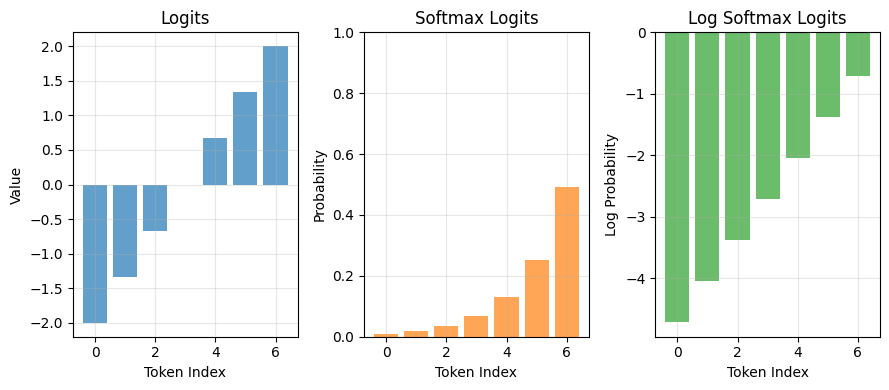

In [38]:
plt.figure(figsize=(9, 4))

plt.subplot(1, 3, 1)
plt.bar(range(len(logits)), logits, color="C0", alpha=0.7)
plt.title("Logits")
plt.xlabel("Token Index")
plt.ylabel("Value")
plt.grid(alpha=0.3)

plt.subplot(1, 3, 2)
plt.bar(range(len(probas)), probas, color="C1", alpha=0.7)
plt.title("Softmax Logits")
plt.xlabel("Token Index")
plt.ylabel("Probability")
plt.ylim(0, 1)
plt.grid(alpha=0.3)

plt.subplot(1, 3, 3)
plt.bar(range(len(log_probas)), log_probas, color="C2", alpha=0.7)
plt.title("Log Softmax Logits")
plt.xlabel("Token Index")
plt.ylabel("Log Probability")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [52]:
@torch.inference_mode()
def calc_next_token_logprobas(model, tokenizer, prompt, device, show=True):
    token_ids = torch.tensor(tokenizer.encode(prompt), device=device)
    logits = model(token_ids.unsqueeze(0)).squeeze(0)
    all_logprobas = torch.log_softmax(logits, dim=-1)
    
    t_idx = torch.arange(0, token_ids.shape[0] - 1, device=device)
    next_ids = token_ids[1:]
    next_token_logprobas = all_logprobas[t_idx, next_ids]
    sum_next_token_logprobas = torch.sum(next_token_logprobas)
    
    if show:
        print("Next token log-probabilities:", next_token_logprobas)
        print("Joint log-probability:", sum_next_token_logprobas)
    else:
        return next_token_logprobas, sum_next_token_logprobas

In [53]:
calc_next_token_logprobas(
    model, tokenizer, device=device,
    prompt="The capital of Germany is Berlin"
)

Next token log-probabilities: tensor([-9.7500, -0.8438, -4.1250, -0.3008, -1.8203], dtype=torch.bfloat16)
Joint log-probability: tensor(-16.8750, dtype=torch.bfloat16)


In [54]:
calc_next_token_logprobas(
    model, tokenizer, device=device,
    prompt="The capital of Germany is Bridge"
)

Next token log-probabilities: tensor([ -9.7500,  -0.8438,  -4.1250,  -0.3008, -15.1875],
       dtype=torch.bfloat16)
Joint log-probability: tensor(-30.2500, dtype=torch.bfloat16)


In [55]:
calc_next_token_logprobas(
    model, tokenizer, device=device,
    prompt="The capital of Germany is Hamburg"
)

Next token log-probabilities: tensor([-9.7500, -0.8438, -4.1250, -0.3008, -3.4375], dtype=torch.bfloat16)
Joint log-probability: tensor(-18.5000, dtype=torch.bfloat16)


In [56]:
example_prompt = "What is the capital of Germany?"
example_answer = " The capital of Germany is Berlin."

next_token_logprobas, sum_next_token_logprobas = calc_next_token_logprobas(
    model, tokenizer, device=device,
    prompt=example_prompt+example_answer,
    show=False
)

print("Next-token logprobas:", next_token_logprobas)
print("Joint log-probability", sum_next_token_logprobas)

Next-token logprobas: tensor([-0.4512, -0.3574, -8.1875, -0.4355, -3.7188, -2.9375, -1.2266,  0.0000,
        -0.0232,  0.0000, -0.0078, -0.0752, -0.1582], dtype=torch.bfloat16)
Joint log-probability tensor(-17.6250, dtype=torch.bfloat16)


In [57]:
print(len(tokenizer.encode(example_answer)))

7


In [58]:
last_7 = next_token_logprobas[-7:]
print(last_7)

tensor([-1.2266,  0.0000, -0.0232,  0.0000, -0.0078, -0.0752, -0.1582],
       dtype=torch.bfloat16)


In [59]:
torch.mean(last_7)

tensor(-0.2129, dtype=torch.bfloat16)

In [60]:
@torch.inference_mode()
def avg_logprob_answer(model, tokenizer, prompt, answer, device="cpu"):
    prompt_ids = tokenizer.encode(prompt)
    answer_ids = tokenizer.encode(answer)
    full_ids = torch.tensor(prompt_ids + answer_ids, device=device)
    
    logits = model(full_ids.unsqueeze(0)).squeeze(0)
    logprobs = torch.log_softmax(logits, dim=-1)
    
    start = len(prompt_ids) - 1
    end = full_ids.shape[0] - 1
    
    t_idx = torch.arange(start, end, device=device)
    next_tokens = full_ids[start+1: end+1]
    next_token_logps = logprobs[t_idx, next_tokens]
    
    return torch.mean(next_token_logps)

In [61]:
score_1 = avg_logprob_answer(
    model, tokenizer, 
    prompt = "What is the capital of Germany?",
    answer = " The capital of Germany is Berlin.",
    device=device
)
print(score_1)

tensor(-0.2129, dtype=torch.bfloat16)


In [62]:
score_1 = avg_logprob_answer(
    model, tokenizer, 
    prompt = "What is the capital of Germany?",
    answer = " The capital of Germany is Bridge.",
    device=device
)
print(score_1)

tensor(-3.8750, dtype=torch.bfloat16)


In [63]:
avg_logprob_answer(
    model, tokenizer,
    prompt=prompt_cot,
    answer=response_1,
    device=device
)

tensor(-0.2285, dtype=torch.bfloat16)

In [64]:
avg_logprob_answer(
    model, tokenizer,
    prompt=prompt_cot,
    answer=response_2,
    device=device
)

tensor(-0.2246, dtype=torch.bfloat16)

In [65]:
raw_prompt = (
    "Half the value of $3x-9$ is $x+37$. "
    "What is the value of $x$?"
)
prompt = render_prompt(raw_prompt)

initial_response = generate_text_stream_concat_flex(
    model, tokenizer, prompt, device,
    max_new_tokens=2048, verbose=True,
    generate_func=generate_text_top_p_stream_cache,
    temperature=0.7,
    top_p=0.9
)

 \boxed{15}

In [66]:
def make_critique_prompt(raw_prompt, draft):
    return (
        "You are a meticulous reviewer. Identify logical errors, missing "
        "steps, or arithmetic mistakes. If the answer seems correct, "
        "say so briefly. Then propose a concise plan to fix issues.\n\n"
        f"Question:\n{raw_prompt}\n\n"
        f"Draft answer:\n{draft}\n\n"
        "Write a short critique and bullet-point fix plan "
        "(under ~120 words).\n"
        "Critique:"
    )
    
critique_prompt = make_critique_prompt(raw_prompt, initial_response)
critique = generate_text_stream_concat_flex(
    model, tokenizer, critique_prompt, device,
    max_new_tokens=2048, verbose=True,
    generate_func=generate_text_top_p_stream_cache,
    temperature=0.7,
    top_p=0.9
)

 The given solution is correct, but there are minor issues with the steps and arithmetic. The equation is half of \(3x - 9\), which is \(1.5(3x - 9)\). This should be equal to \(x + 37\), so the equation becomes \(1.5(3x - 9) = x + 37\).

Solution:
\[
1.5(3x - 9) = x + 37
\]
\[
4.5x - 13.5 = x + 37
\]
\[
4.5x - x = 37 + 13.5
\]
\[
3.5x = 50.5
\]
\[
x = \frac{50.5}{3.5} = 14.42857 \approx 15
\]

Fix Plan: Ensure all calculations are accurate and double-check the algebraic manipulation to avoid errors.

In [67]:
def make_refine_prompt(raw_prompt, draft, critique):
    return (
        "Revise the answer using the critique. Keep it concise and "
        "end with a final boxed result: \\boxed{ANSWER}\n\n"
        f"Question:\n{raw_prompt}\n\n"
        f"Previous answer:\n{draft}\n\n"
        f"Critique:\n{critique}\n\n"
        "Revised answer:"
    )
    
refine_prompt = make_refine_prompt(raw_prompt, initial_response, critique)
revised_answer = generate_text_stream_concat_flex(
    model, tokenizer, refine_prompt, device,
    max_new_tokens=2048, verbose=True,
    generate_func=generate_text_top_p_stream_cache,
    temperature=0.7,
    top_p=0.9
)

 \boxed{15}

In [78]:
def self_refinement_loop(
    model,
    tokenizer, 
    raw_prompt,
    device, 
    iterations=2,
    max_response_tokens=2048,
    max_critique_tokens=256,
    score_fn=None,
    prompt_renderer=render_prompt,
    prompt_suffix="",
    verbose=False,
    temperature=0.7,
    top_p=0.9,
):
    steps = []
    
    prompt = prompt_renderer(raw_prompt) + prompt_suffix
    current_full = generate_text_stream_concat_flex(
        model=model,
        tokenizer=tokenizer, 
        prompt=prompt,
        device=device, 
        max_new_tokens=max_response_tokens,
        verbose=False,
        generate_func=generate_text_top_p_stream_cache,
        temperature=temperature,
        top_p=top_p,
    )
    
    current_extracted = extract_final_candidate(current_full, fallback="number_then_full")
    if score_fn:
        current_score = score_fn(answer=current_full, prompt=prompt)
    else:
        current_score = 0.0
        
    for it in range(iterations):
        draft_before_full = current_full
        draft_before_extracted = current_extracted
        score_before = current_score
        
        critique_prompt = make_critique_prompt(raw_prompt, draft_before_full)
        critique_full = generate_text_stream_concat_flex(
            model=model,
            tokenizer=tokenizer, 
            prompt=critique_prompt,
            device=device, 
            max_new_tokens=max_critique_tokens,
            verbose=False,
            generate_func=generate_text_top_p_stream_cache,
            temperature=temperature,
            top_p=top_p,
        )
        
        refine_prompt = make_refine_prompt(raw_prompt, draft_before_full, critique_full)
        revised_full = generate_text_stream_concat_flex(
            model=model,
            tokenizer=tokenizer, 
            prompt=refine_prompt,
            device=device, 
            max_new_tokens=max_response_tokens,
            verbose=False,
            generate_func=generate_text_top_p_stream_cache,
            temperature=temperature,
            top_p=top_p,
        )
        
        revised_extracted = extract_final_candidate(revised_full, fallback="number_then_full")
        if score_fn:
            revised_score = score_fn(answer=revised_full, prompt=prompt)
        else:
            current_score = 0.0
            
        step = {
            "iteration": it + 1,
            "draft_full": draft_before_full,
            "draft_extracted": draft_before_extracted,
            "critique": critique_full,
            "revised_full": revised_full,
            "revised_extracted": revised_extracted,
            "score_before": score_before,
            "score_after": revised_score,
        }
        steps.append(step)
        
        if verbose:
            print(
                f"[Refinement {it+1}/{iterations}]"
                f"\nCurrent: {draft_before_extracted}"
                f"\nRevised: {revised_extracted}"
                f"\nScore before: {score_before:.3f}"
                f"\nScore after: {revised_score:.3f}"
                f"\n{'=' * 25}"
            )
            
        if revised_score >= current_score:
            current_full = revised_full
            current_extracted = revised_extracted
            current_score = revised_score
            
    return {
        "final_full": current_full, 
        "final_extracted": current_extracted,
        "steps": step
    }  

In [76]:
from functools import partial 

avg_logprob_score = partial(
    avg_logprob_answer,
    model=model,
    tokenizer=tokenizer,
    device=device
)

In [79]:
results_logprob = self_refinement_loop(
    model=model,
    tokenizer=tokenizer, 
    raw_prompt=raw_prompt,
    device=device, 
    iterations=2,
    max_response_tokens=2048,
    max_critique_tokens=256,
    score_fn=avg_logprob_score,
    verbose=True,
    temperature=0.7,
    top_p=0.9,
)

[Refinement 1/2]
Current: 56
Revised: 1
Score before: -1.391
Score after: -1.234
[Refinement 2/2]
Current: 1
Revised: 1
Score before: -1.234
Score after: -1.500


In [80]:
print(results_logprob["final_extracted"])

1
